In [ ]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

--2026-10-12 19:22:30--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  --.-KB/s    in 0.05s   

2026-10-12 19:22:30 (20.1 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F

In [ ]:
# hyperparameters
batch_size = 64  # how many independent sequences will we process in parallel?
'''
why use batch:
1. better utilization of the GPU
2. more training exmaples contribute to each gradient update
3. more memory is required as the batch grows
Note: these are independent sample block
'''
block_size = 256  # what is the maximum context length for predictions?, now it will consider 256 char to predict 257th
'''
both above construct our input shape
B = batch_size
T = block_size

(B,T) = (64,256)

there is also another thing that is the vocaburary size
C = vocab_size

B T C :
b no. of parallel execution
each b has t no. of context lengh
each t no. of context lengh has c no. of characters (think of these like representation of those context lengh over c no. of characters)
'''
max_iters = 5000 # no. of training iteration, and this many no. of optimizer updates
eval_interval = 500 #this is interval at which we check the model evaluation
# ie at 0, 500, 1000, 1500 and so on, we get the eval rate
learning_rate = 3e-4
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 384 # means no. of embedding dim, think of this like a 8 bit or 10 bit colors
# this n embd can be any thing perhaps
n_head = 6 # 384/6 = 64,ie every head is 64 dim long
n_layer = 6
dropout = 0.2 # it's a regularization technique, used to prevent overfitting, read its paper

In [ ]:
torch.manual_seed(1337)

# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars) # this is the C part in out input
# create a mapping from characters to integers
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]  # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l])  # decoder: take a list of integers, output a string

# Train and test splits
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))  # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]

In [ ]:
# data loading, nothing but a batch generator
def get_batch(split): # every time this is called, it returns a random values (a list of size n where n = batch_size, ie 4 parallel worker required 4 parallel initial index)
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    # so we want to randonly initialize the starting point of this batch generator,
    # we get random initial data as when we train the model in parallel, We want different portions of the text in each batch, rather than repeatedly training on the same beginning
    x = torch.stack([data[i:i + block_size] for i in ix])
    # lets say ix is [0,23,98,119]
    # ie i is 0 and block size is 8, ie x is from 0 to 8
    y = torch.stack([data[i + 1:i + block_size + 1] for i in ix]) # now y becomes 1 to 9 ie, for each element of x the predicting element is y
    # for x=0 predicting element is y=1 ie the next 'token'
    x, y = x.to(device), y.to(device)
    return x, y

In [ ]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

In [ ]:
class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        B,T,C = x.shape
        k = self.key(x) # (B,T,C)
        q = self.query(x) # (B,T,C)
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * C **-0.5 # (B, T, C) @ (B, C, T) ---> (B, T, T)
        # format: .transpose(dim1, dim2) this is a swap, we mention which 2 dim will switch place, and we chose 2nd last and last, now it will switch those 2
        # and it will be B,T,C, why we do this is because:
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T) #
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,C)
        out = wei @ v # (B, T, T) @ (B, T, C) -> (B, T, C)
        return out

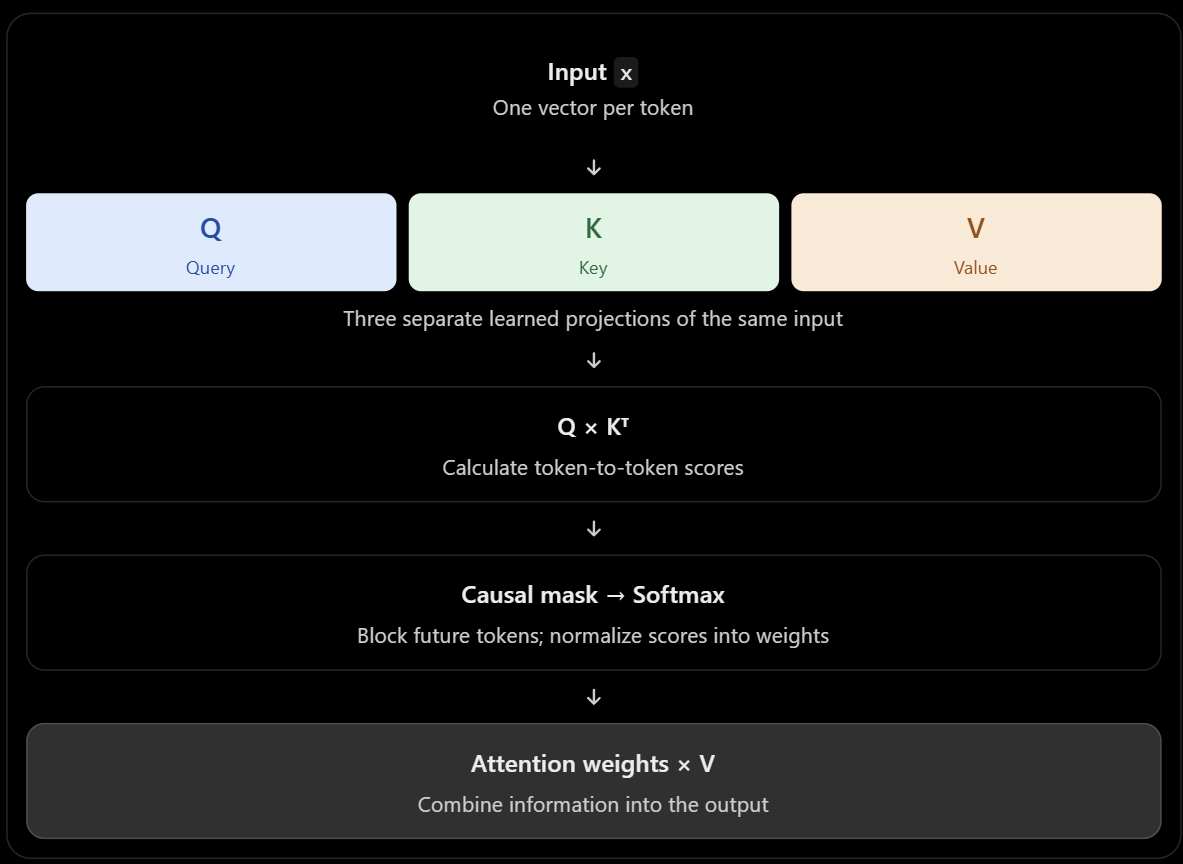

In [ ]:
class MultiHeadAttention(nn.Module):
    ''' Multi-Head Attention '''
    def __init__(self, num_head, head_size):
        super().__init__()
        self.heads=nn.ModuleList([Head(head_size) for _ in range(num_head)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1) # we are concatening over the channel dimension over a list
        out = self.dropout(self.proj(out))
        return out

class FeedForward(nn.Module):
    ''' FeedForward: a simple linear layer followed by a non-linearity '''
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4* n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd), # this is the projection layer
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
class Block(nn.Module):
    ''' Transformer block: communication followed by computation '''

    def __init__(self, n_embd, n_head):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head # n_embd is 32, so we keep n_head = 4 so that head_size is 8 and it works out
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd) # the size of the layer num is n embd = 32
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

In [ ]:
class BigramLanguageModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
    self.position_embedding_table = nn.Embedding(block_size, n_embd)
    self.block = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
    # ----------------------- xox -----------------------
    self.ln_f = nn.LayerNorm(n_embd)
    self.lm_head = nn.Linear(n_embd, vocab_size)

  def forward(self, idx, targets=None):
    B,T = idx.shape
    tok_emb = self.token_embedding_table(idx)
    pos_emb = self.position_embedding_table(torch.arange(T, device=device))
    x = tok_emb + pos_emb
    x = self.block(x) # x updating itself
    logits = self.lm_head(x)
    if targets is None:
      loss = None
    else:
      B, T, C = logits.shape
      logits = logits.view(B*T, C)
      targets = targets.view(B*T)
      loss = F.cross_entropy(logits, targets)
    return logits, loss

  def generate(self, idx, max_new_tokens):
    for _ in range(max_new_tokens):
      # crop idx to the last block size tokens
      idx_cond = idx[:, -block_size:]
      # get the predictions
      logits, loss = self(idx_cond)
      # focus only on the last time step
      logits = logits[:, -1, :] # becomes (B, C)
      # apply softmax to get probabilities
      probs = F.softmax(logits, dim=-1) # (B, C)
      # sample from the distribution
      idx_next = torch.multinomial(probs, num_samples=1)  # (B, 1)
      # append sampled index to the running sequence
      idx = torch.cat((idx, idx_next), dim=1)  # (B, T+1)
    return idx

In [ ]:
model = BigramLanguageModel() # (vocab_size) even here no need
m = model.to(device)

# create a PyTorch optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

for iter in range(max_iters):

    # every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# generate from the model
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=500)[0].tolist()))


step 0: train loss 4.4753, val loss 4.4709
step 500: train loss 2.0851, val loss 2.1484
step 1000: train loss 1.6603, val loss 1.8271
step 1500: train loss 1.4891, val loss 1.6835
step 2000: train loss 1.3871, val loss 1.6086
step 2500: train loss 1.3179, val loss 1.5587
step 3000: train loss 1.2611, val loss 1.5226
step 3500: train loss 1.2132, val loss 1.5001
step 4000: train loss 1.1756, val loss 1.4892
step 4500: train loss 1.1371, val loss 1.4821

Had you to have him had swift his health,
And yet 'He'll vouches, you are twill us o' the
heavens front him: the gods and thought not home,
How he did raise you present with ay yours?

VIRGILIA:
An is your prevail's home office
Have nobourn'd that wastemed with ground and tree--

SICIO::
Then was I mine, even so, what do not speak?
Seed my death, hence withal a crutch.

VALERIA:
The king of Clarence am he; stabb'd my wife, sir
to finst the modested in the most life merife, what
the dukest, I did


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def run_experiment(experiment_name, custom_hyperparams={}):
    # Temporary global override for experiment configurations
    current_lr = custom_hyperparams.get('learning_rate', learning_rate)
    current_max_iters = custom_hyperparams.get('max_iters', 1500)  # Shorter iterations for quick benchmarking

    # Re-initialize model to ensure fresh weights
    exp_model = BigramLanguageModel().to(device)
    optimizer = torch.optim.AdamW(exp_model.parameters(), lr=current_lr)

    history = []

    for iter in range(current_max_iters):
        if iter % eval_interval == 0:
            # Override global model temporarily for estimate_loss
            global model
            old_model = model
            model = exp_model
            losses = estimate_loss()
            model = old_model

            history.append({
                'experiment': experiment_name,
                'step': iter,
                'train_loss': losses['train'].item(),
                'val_loss': losses['val'].item()
            })
            print(f"[{experiment_name}] step {iter}: train {losses['train']:.4f}, val {losses['val']:.4f}")

        xb, yb = get_batch('train')
        logits, loss = exp_model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    return pd.DataFrame(history)

In [ ]:
# Run a suite of baseline experiments to compare parameters
results = []

# Experiment 1: Baseline (lr=3e-4)
df_baseline = run_experiment('baseline_lr_3e-4', {'learning_rate': 3e-4, 'max_iters': 1500})
results.append(df_baseline)

# Experiment 2: Higher learning rate (lr=1e-3)
df_high_lr = run_experiment('high_lr_1e-3', {'learning_rate': 1e-3, 'max_iters': 1500})
results.append(df_high_lr)

# Comb00000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000cat(results, ignore_index=True)
display(all_results_df.head(10))

[baseline_lr_3e-4] step 0: train 4.6321, val 4.6388
[baseline_lr_3e-4] step 500: train 2.0592, val 2.1183
[baseline_lr_3e-4] step 1000: train 1.6458, val 1.8066
[high_lr_1e-3] step 0: train 4.5017, val 4.5058
[high_lr_1e-3] step 500: train 1.7650, val 1.8930
[high_lr_1e-3] step 1000: train 1.4413, val 1.6430


,experiment,step,train_loss,val_loss
0,baseline_lr_3e-4,0,4.632084,4.638785
1,baseline_lr_3e-4,500,2.059209,2.118286
2,baseline_lr_3e-4,1000,1.645755,1.806584
3,high_lr_1e-3,0,4.501721,4.505843
4,high_lr_1e-3,500,1.765026,1.893040
5,high_lr_1e-3,1000,1.441271,1.642972


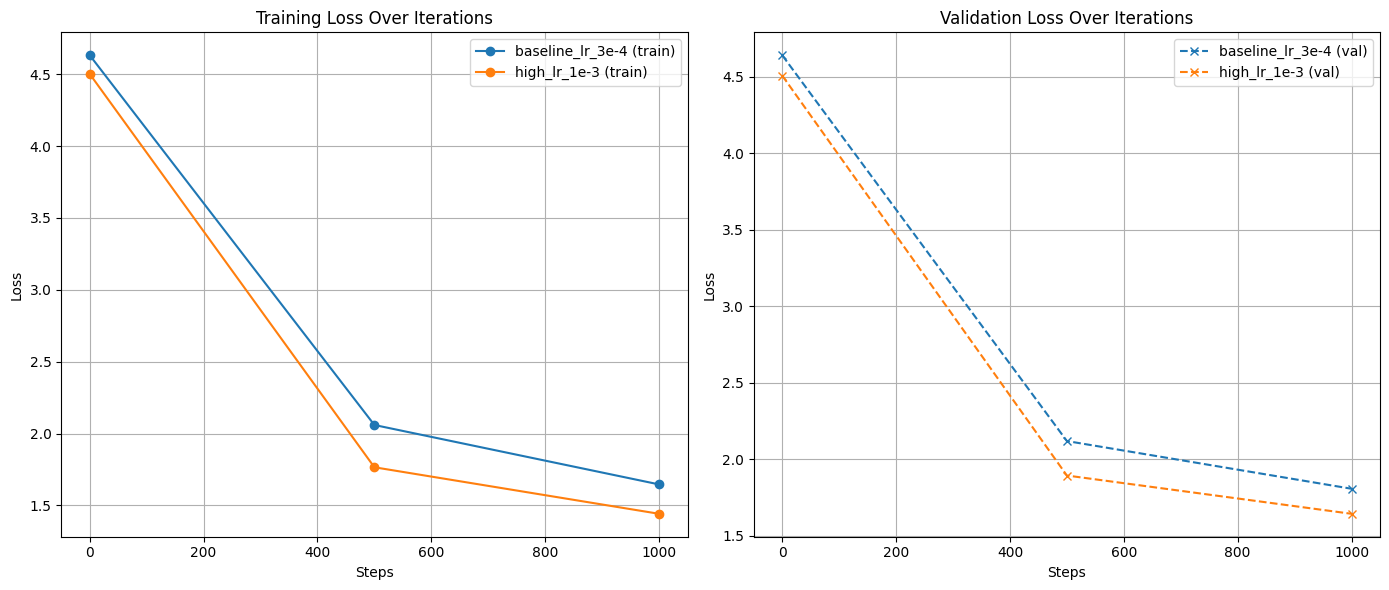

In [ ]:
# Plot the training and validation curves for each experiment
plt.figure(figsize=(14, 6))

# Plot Train Loss
plt.subplot(1, 2, 1)
for name, group in all_results_df.groupby('experiment'):
    plt.plot(group['step'], group['train_loss'], label=f'{name} (train)', marker='o')
plt.title('Training Loss Over Iterations')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Val Loss
plt.subplot(1, 2, 2)
for name, group in all_results_df.groupby('experiment'):
    plt.plot(group['step'], group['val_loss'], label=f'{name} (val)', linestyle='--', marker='x')
plt.title('Validation Loss Over Iterations')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()